# Forecast 1 — Linear Reservoir Streamflow Forecast

CEE 306: Hydrology — Water and Climate | Spring 2026

This notebook documents our team’s streamflow forecast for Stony Brook using a linear reservoir model. Course-provided assignment prompts have been omitted; the original code, results, and team interpretations have been retained.

**Forecast Team Name:** `<HBO>`

**Names:** `<Sayfullo Saidov, Muhammad Omer, Wunnyuriti Ziblim>`

**Forecasted Dates:** `<March 6-8, 2026>`

#### Import Functions

In [1]:
import pandas as pd
import numpy as np
import json, requests
import matplotlib.pyplot as plt

## Most Recent Weather Forecast and Historical Flow Data

In [2]:
## get the forecast for temperature and precipitation
headers = {
'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/71.0.3578.98 Safari/537.36',
'Accept' : 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8',
'Accept-Language' : 'en-US,en;q=0.5',
'Accept-Encoding' : 'gzip',
'DNT' : '1', # Do Not Track Request Header
'Connection' : 'close' }
url = requests.get("https://api.weather.gov/gridpoints/PHI/63,95/", headers=headers)

data_json = json.loads(url.text)

data = pd.DataFrame(columns=('DateTime','Precip [mm]','Temp [C]'))
for i in range(12):
    data.loc[i] = [data_json['properties']['quantitativePrecipitation']['values'][i]['validTime'],
                   data_json['properties']['quantitativePrecipitation']['values'][i]['value'],
                   data_json['properties']['temperature']['values'][i]['value']]

# note the cumulative sum calculations and conversions below
data['DateTime'] = data['DateTime'].str.slice(stop=16)
data['cum_precip_mm'] = data['Precip [mm]'].cumsum()
data['Precip_ft'] = data['Precip [mm]']*0.00328084
data['Precip_in'] = data['Precip [mm]']*0.0393701
data['cum_precip_in'] = data['Precip_in'].cumsum()

In [3]:
## now let's get past week of streamflow and precipitation - using the same url process as before
# Remember time period code convention: "P7D" means past 7 days, while "P30D" means past 30 days etc.
period = "P7D"
# agian, feel free to print and look at those URLs

# streamflow from Stony Brook
flow_url = "https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=01401000&period="+period+"&parameterCd=00060&siteStatus=all"
StonyBrook = pd.read_csv(flow_url, skiprows=28, sep='\t', header=None)
StonyBrook.columns = ["agency_cd","site_no","datetime_stony","tz_cd","flow_cfs","194689_00060_cd"]

# precip from Skillman
precip_url = "https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=402504074414201&period="+period+"&parameterCd=00045&siteStatus=all"
Skillman = pd.read_csv(precip_url, skiprows=28, sep='\t', header=None)
Skillman.columns = ["agency_cd","site_no","datetime_skill","tz_cd","precip_in","Cumulative_Precip"]
Skillman['cum_precip_in'] = Skillman['precip_in'].cumsum()

# air temperature from Trenton
airtemp_url = "https://waterdata.usgs.gov/nwis/uv?cb_00021=on&format=rdb&site_no=401121074452101&period="+period
Trenton = pd.read_csv(airtemp_url, skiprows=25, sep='\t', header=None)
Trenton.columns = ['agency_cd','site_no',"datetime_trent","tz",'airTemp_F','description']

# if you want, uncomment the below code to see the csv url links, and a sample of the dataframes
print(f'Streamflow csv URL: {flow_url}')
print(StonyBrook.head(5),'\n')
print(f'Precipitation csv URL: {precip_url}')
print(Skillman.head(5),'\n')
print(f'Air temperature URL: {airtemp_url}')
print(Trenton.head(5),'\n')


Streamflow csv URL: https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=01401000&period=P7D&parameterCd=00060&siteStatus=all
  agency_cd  site_no    datetime_stony tz_cd  flow_cfs 194689_00060_cd
0      USGS  1401000  2026-02-27 02:30   EST      77.4               P
1      USGS  1401000  2026-02-27 02:45   EST      78.9               P
2      USGS  1401000  2026-02-27 03:00   EST      78.9               P
3      USGS  1401000  2026-02-27 03:15   EST      78.9               P
4      USGS  1401000  2026-02-27 03:30   EST      80.4               P 

Precipitation csv URL: https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=402504074414201&period=P7D&parameterCd=00045&siteStatus=all
  agency_cd          site_no    datetime_skill tz_cd  precip_in  \
0      USGS  402504074414201  2026-02-27 02:30   EST        0.0   
1      USGS  402504074414201  2026-02-27 02:45   EST        0.0   
2      USGS  402504074414201  2026-02-27 03:00   EST        0.0   
3      USGS  402504074414201  20

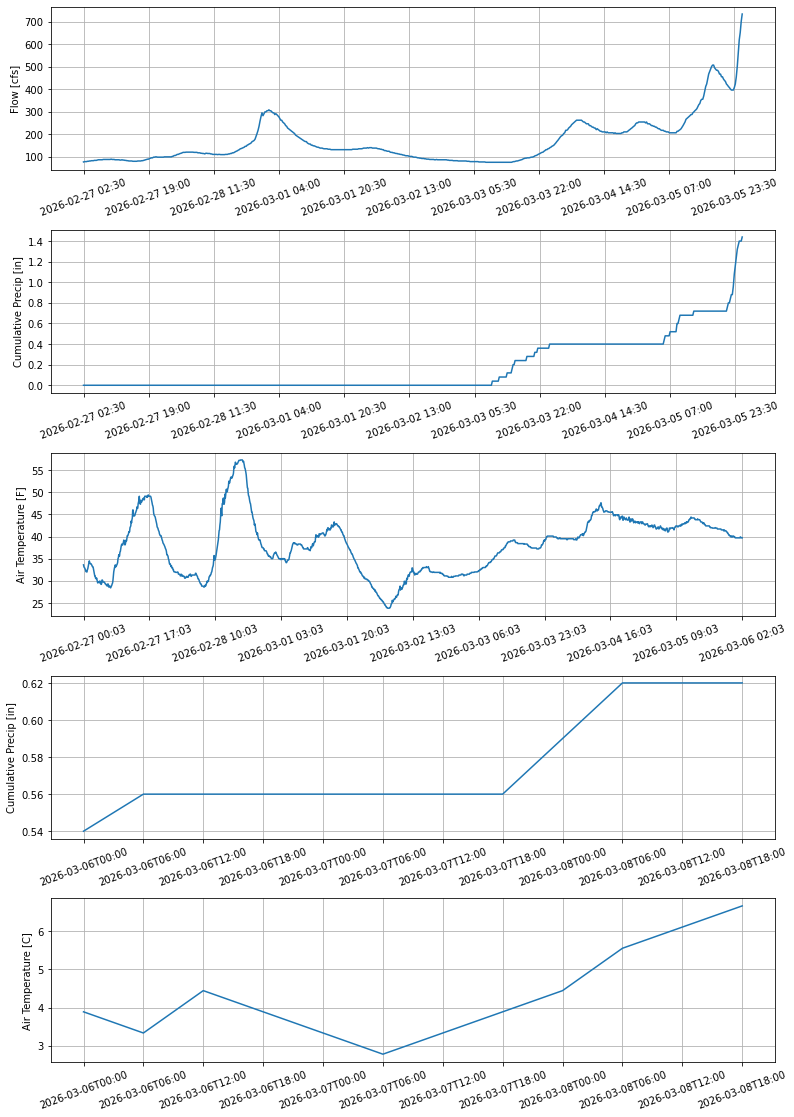

In [4]:
## plot data
## set up figure with 4 plots
fig, axs = plt.subplots(5,figsize=(12,16))

## plot past streamflow
axs[0].plot(StonyBrook['datetime_stony'],StonyBrook['flow_cfs'])
axs[0].set_xticks(StonyBrook['datetime_stony'][::len(StonyBrook['datetime_stony']) // 10])
axs[0].set_ylabel('Flow [cfs]')

## plot past precipitation
axs[1].plot(Skillman['datetime_skill'],Skillman['cum_precip_in'])
axs[1].set_xticks(Skillman['datetime_skill'][::len(Skillman['datetime_skill']) // 10])
axs[1].set_ylabel('Cumulative Precip [in]')

## plot past air temperature
axs[2].plot(Trenton['datetime_trent'],Trenton['airTemp_F'])
axs[2].set_xticks(Trenton['datetime_trent'][::len(Trenton['datetime_trent']) // 10])
axs[2].set_ylabel('Air Temperature [F]')

## plot forecast precip
axs[3].plot(data['DateTime'],data['cum_precip_in'])
axs[3].set_ylabel('Cumulative Precip [in]')

## plot forecast air temp
axs[4].plot(data['DateTime'],data['Temp [C]'])
axs[4].set_ylabel('Air Temperature [C]')

# put space between plots
fig.tight_layout(pad=4.0)

# add a grid and rotate the x-axis labels on each plot
for i in range(5):
    axs[i].grid()
    axs[i].tick_params(axis='x', labelrotation = 20)

## Linear Reservoir Model and Forecast Calculations

In [5]:
data

,DateTime,Precip [mm],Temp [C],cum_precip_mm,Precip_ft,Precip_in,cum_precip_in
0,2026-03-06T00:00,13.716001,3.888889,13.716001,0.045000,0.54,0.54
1,2026-03-06T06:00,0.508000,3.333333,14.224001,0.001667,0.02,0.56
2,2026-03-06T12:00,0.000000,4.444444,14.224001,0.000000,0.00,0.56
3,2026-03-06T18:00,0.000000,3.888889,14.224001,0.000000,0.00,0.56
4,2026-03-07T00:00,0.000000,3.333333,14.224001,0.000000,0.00,0.56
5,2026-03-07T06:00,0.000000,2.777778,14.224001,0.000000,0.00,0.56
6,2026-03-07T12:00,0.000000,3.333333,14.224001,0.000000,0.00,0.56
7,2026-03-07T18:00,0.000000,3.888889,14.224001,0.000000,0.00,0.56
8,2026-03-08T00:00,0.762000,4.444444,14.986001,0.002500,0.03,0.59
9,2026-03-08T06:00,0.762000,5.555556,15.748000,0.002500,0.03,0.62


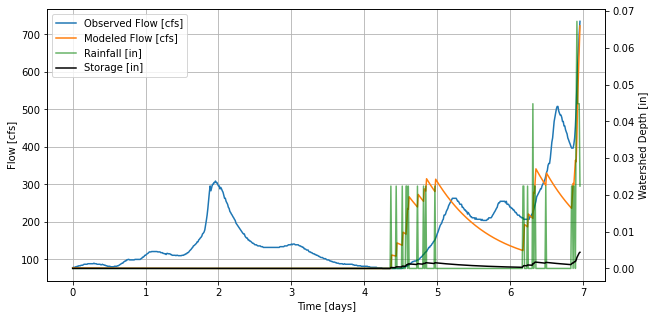

RMSE: 85.60235711167896 cfs


count    669.000000
mean     167.988789
std      103.097671
min       75.900000
25%       91.400000
50%      132.000000
75%      218.000000
max      735.000000
Name: flow_cfs, dtype: float64

In [6]:
# watershed parameters from HW1
area = 44.5 * 2.788e7      # watershed area [ft^2]
dt = 0.25/24               # 15-minute timestep (days) as we see on the given data above
T_star = 0.75              # residence time (days). Just reusing the value from HW1

ET_factor = 0.8            #Estimation given by HW1
runoff_coeff = 0.7         #Considering the fact that there are also other ways for water to 'escape' not to enter the runoff 

# number of time steps
n_tsteps = len(StonyBrook)   #as we are diving it by 15 minutes timescale

# converting observed flow to watershed depth [inches per timestep]

# V = storage in inches as our choice
# w = rainfall input in inches per timestep
# q = outflow in inches per timestep


StonyBrook['flow_in'] = StonyBrook['flow_cfs'] * 12 * 900 / area

# initialize arrays
time = np.arange(n_tsteps) * dt
V = np.zeros(n_tsteps)
q = np.zeros(n_tsteps)
w = np.zeros(n_tsteps)

# observed flow depth
q_obs = StonyBrook['flow_in'].values

# rainfall input
w[:len(Skillman)] = Skillman['precip_in'].values * ET_factor * runoff_coeff


# rainfall lag (1 hour = 5 steps) as we thought that in real life it takes some time for rainfall water to be logged onto flow sensors

lag = 5
w = np.roll(w, lag)
w[:lag] = 0

# baseflow separation #we also took into account the fact that there is a baseflow in most cases when no rain is happening. So, it cannot be neglected.
baseflow = np.min(q_obs)
q_quick = q_obs - baseflow
q_quick[q_quick < 0] = 0

# initial conditions is with baseflow
V[0] = q_quick[0] * T_star
q[0] = q_quick[0]

# Euler linear reservoir simulation from HW1 etc.
for i in range(1, n_tsteps):

    q[i] = V[i-1] / T_star

    V[i] = V[i-1] + (w[i] - q[i]) * dt

    V[i] = max(V[i], 0)

# adding baseflow back
q_total = q + baseflow

# converting modeled flow back to cfs
q_cfs = q_total * area / (12 * 900)
q_obs_cfs = q_obs * area / (12 * 900)

# plot
fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(time, q_obs_cfs, label='Observed Flow [cfs]')
ax1.plot(time, q_cfs, label='Modeled Flow [cfs]')
ax1.set_xlabel('Time [days]')
ax1.set_ylabel('Flow [cfs]')
ax1.grid()

ax2 = ax1.twinx()
ax2.plot(time, w, color='green', alpha=0.6, label='Rainfall [in]')
ax2.plot(time, V, color='black', label='Storage [in]')
ax2.set_ylabel('Watershed Depth [in]')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)

plt.show()

# RMSE (more validation methods are explored in the final question)
rmse = np.sqrt(np.mean((q_obs_cfs - q_cfs)**2))
print("RMSE:", rmse, "cfs")

StonyBrook['flow_cfs'].describe()   #just for reference, printing

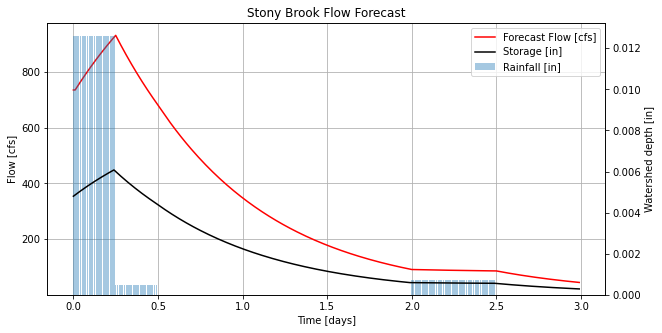

In [13]:
forecast_days = 3
dt = 0.25/24                 
dt_data = 6/24               # forecast data interval (6 hours) which is different from stonybrook or skillman. we need to consider this. 

n_tsteps = int(forecast_days / dt) #based on that, we can divide and have steps

time_forecast = np.arange(n_tsteps) * dt #each step x each time interval that it calculates

# initializing arrays
V_f = np.zeros(n_tsteps)
q_f = np.zeros(n_tsteps)
w_f = np.zeros(n_tsteps)

#Initial condition

last_q = q_obs[-1]           # we decided to start from last observed flow depth instead of just 0 
V_f[0] = last_q * T_star
q_f[0] = last_q

#Building rainfall input (we realized that not having lag nor baseflow in this prediction didn't cause a big change. 
#So, for simplification, we decided them to be redundant for this specific case. 

forecast_precip = data['Precip_in'].values * ET_factor * runoff_coeff

steps_per_row = int(dt_data / dt)

w_f = np.repeat(forecast_precip / steps_per_row, steps_per_row)

w_f = w_f[:n_tsteps]

#Linear reservoir model

for i in range(1, n_tsteps):

    q_f[i] = V_f[i-1] / T_star

    V_f[i] = max(V_f[i-1] + (w_f[i] - q_f[i]) * dt, 0)

#Convert to cfs like previously

q_f_cfs = q_f * area / (12 * 900)

#Plot

fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(time_forecast, q_f_cfs, color='red', label='Forecast Flow [cfs]')
ax1.set_xlabel('Time [days]')
ax1.set_ylabel('Flow [cfs]')
ax1.grid()

ax2 = ax1.twinx()
ax2.bar(time_forecast, w_f, width=dt*0.8, alpha=0.4, label='Rainfall [in]')
ax2.plot(time_forecast, V_f, color='black', label='Storage [in]')
ax2.set_ylabel('Watershed depth [in]')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)

plt.title("Stony Brook Flow Forecast")
plt.show()

In [14]:
steps_per_day = int(1/dt)

Friday = q_f_cfs[:steps_per_day].mean()
Saturday = q_f_cfs[steps_per_day:2*steps_per_day].mean()
Sunday = q_f_cfs[2*steps_per_day:3*steps_per_day].mean()

print("Friday:", Friday)
print("Saturday:", Saturday)
print("Sunday:", Sunday)

Friday: 658.1617961757737
Saturday: 192.7883507649336
Sunday: 75.48217655719172


## Our Prediction

**Friday:** `<658.16 cfs>` <br>
**Saturday:** `<192.79 cfs>` <br>
**Sunday:** `<75.48 cfs>`

## Forecast Method

`<We used a numerical linear reservoir model to create this forecast. This uses the Euler integration form of the linear reservoir model, where the storage updates based on previous storage and the difference between precipitation and outflow per timestep.
To implement this model, we first “hindcast” to the past seven days and compared it to historical data. We used the same timestep as the Stony Brook and Skillman datasets (15 minute intervals), so our dt was 0.25 hour per 24 hours (0.25/24). We then used the same T_star value of 0.75 and the same ET factor of 0.8 (as was used in Homework 1). We chose these as our initial values because Homework 1 was also based in the Stony Brook watershed. However, after testing various T-star and ET factor values, we found these values fit the actual data the best. We also decided to add the factor of runoff coefficient as we thought except for ET factor of 0.8 (which is already substantially simplied as a constant), there are different paths rainfall takes that do not contribute directly to the runoff. We estimated this value to be 0.7 (through checking various options to see how RMSE changes). We then ran the numerical solution using a for-loop and Skillman precipitation data. We then created forecasts using a similar method. Instead of hindcasting the past seven days, we ran our simulation over three days. The forecast data was derived from the “data” array of NWS. Our first data point for storage was derived from the last data point from our hindcast, and the first data point for our outflow was derived from the last outflow data point from the actual Stony Brook data.>`

## Comparison with Previous Forecast

`<This forecast used a specific hydrological model instead of correlating increases in rainfall to increases in streamflow. Our previous forecast had rough quantitative foundations and guessed that streamflow increase and precipitation increase were proportional. This model uses the linear reservoir principle, which takes one parameter to produce a hydrograph. Since this has basis in a mathematical model, the relationships between precipitation, outflow, and storage have better scientific basis. However, this model is limited by over-simplifications in the linear reservoir model. In addition, streamflow only reacts to changes in precipitation. The T_star parameter lacks physical representation and true hydrological systems are not linear. For example, our T_star is estimated as 0.75 because we expect that natural geographic and infiltration characteristics of the Stony Brook watershed will cause a slower response time to precipitation. Our ET value of 0.8 & runoff coefficient of 0.7 also are rough estimations of the precipitation that ends up as outflow. Finally, a large uncertainty comes from the linear reservoir’s sole dependence on precipitation. We can see from the historical data that there is a large fluctuation in streamflow on March 1st absent of precipitation. This implies other factors, such as air temperature and snow melt may impact outflow, which is not accounted for by the linear reservoir model. >`

## Assessment of Forecast Approach

`<Yes, this forecast is better than our first forecast. By using the model, we can quantitatively generate streamflow predictions for the next three days, rather than relying on intuition alone. While previous method relied on guessing without considering how water moves through the watershed, this task's linear reservoir model accounts for watershed storage, outflow proportionality to storage, and the effect of rainfall over time. While ET and Runoff coeff. might be a constant that are simplified version of the real system, it is relatively closer to the realistic conditiosn. >`

## Model Validation

In [15]:
#Validation metrics

obs = q_obs_cfs[:len(q_cfs)]
mod = q_cfs

mask = ~np.isnan(obs) & ~np.isnan(mod)
obs = obs[mask]
mod = mod[mask]

# statistics
obs_mean = obs.mean()

NSE = 1 - np.sum((obs - mod)**2) / np.sum((obs - obs_mean)**2)
PBIAS = 100 * np.sum(obs - mod) / np.sum(obs)
RMSE = np.sqrt(np.mean((obs - mod)**2))

print(f"Nash-Sutcliffe Efficiency : {NSE:.3f}")
print(f"Percent Bias              : {PBIAS:.2f}%")
print(f"RMSE                      : {RMSE:.2f} cfs")

Nash-Sutcliffe Efficiency : 0.310
Percent Bias              : 20.04%
RMSE                      : 85.60 cfs


`<We used different validation methods discussed in class slides. We validated through comparing the modeled streamflow to observed Stony Brook flows over the past seven days. The model produced a Nash–Sutcliffe Efficiency (NSE) of 0.310, indicating a fairly modest skill in capturing flow variability (where 1 is considered to be the perfect). Percent Bias (PBIAS) was 20.0%, indicating that our model slightly underestimates flows (as it can be seen on the first graph), and the Root Mean Square Error (RMSE) was 85.6 cfs, which is reasonable given the simplicity and uncertainty reasons of the single-reservoir representation. Overall, the validation metrics indicate that the model is capturing general reaction but not fully realizing the effect of certain extreme peaks, baseflow, or events like snowmelt.>`

### Acknowledgement 

We utilized AI to ask methods for baseflow and lag - something new we thought we could add that we didn't do on HW1 & also asked it to give us formula for different validation method. We also had an error with confusing timescale (15 min, 6 hours, etc) so asked AI to debug certain parts of our model